# 05 · Benchmark complet et études de confirmation

**Bloc 5 · W37 : mini-projet éCO2mix, notebook complémentaire.**

Les notebooks 03 et 04 ont abouti à trois conclusions :

1. **Le bottom-up est la meilleure réconciliation** sur cette hiérarchie (12 régions → France).
2. **MinT shrink fait moins bien que le bottom-up**, parce que sa matrice W est estimée sur des résidus
   in-sample de MSTL qui ne ressemblent pas aux vraies erreurs de prévision.
3. **Le levier principal est le modèle de base**, pas la réconciliation.

Ce notebook les met à l'épreuve de deux façons. D'abord un **benchmark complet** : toutes les solutions
étudiées, face à des baselines naïves et statistiques et à la prévision officielle de RTE, avec des courbes qui
montrent *où* se fait le gain (par heure, par mois, par métrique). Ensuite des **études de confirmation**, qui
changent une seule chose à la fois : le nombre d'origines, l'année, le modèle de base, la façon d'estimer W.

| § | Question | Ce qui change |
|---|---|---|
| 1 | Qui sont les concurrents ? | 4 baselines naïves, 1 modèle statistique, 5 réconciliations, 2 repères RTE |
| 2 | D'où vient le gain ? | l'escalier du benchmark, du naïf à RTE |
| 3 | Le gain dépend-il de l'heure prévue ? | courbes par horizon (1 à 24 h) |
| 4 | Le gain dépend-il de la saison ? | courbes mois par mois |
| 5 | Le classement dépend-il de la métrique ? | MASE, MAE, RMSE, MAPE |
| 6 | Combien d'origines faut-il pour conclure ? | convergence du gain |
| 7 | Confirmation 1 : une autre année | backtest complet sur 2023 |
| 8 | Confirmation 2 : un autre modèle de base | AutoETS au lieu de MSTL |
| 9 | Confirmation 3 : la cause, W | W hors échantillon, sur 2023 et selon la taille de la fenêtre |
| 10 | Synthèse | ce qui est confirmé, ce qui est nuancé |

Les backtests tournent en ligne de commande (`make eco2mix-robustness` puis `make eco2mix-confirmation`) ; ce
notebook relit leurs résultats et ajoute les baselines naïves et RTE, qui ne demandent aucun entraînement.

> **Comment lire ce notebook.** Les encadrés suivent le code du dépôt :
> **Intuition**, l'idée sans les équations · **Exemple**, une expérience chiffrée ·
> **Point d'attention**, le piège à éviter · **À retenir**, le mémo à garder.
>
> **Code couleur des courbes, fixe dans tout le notebook.** Bleu = bottom-up (méthode recommandée) ·
> orange = MinT shrink (méthode de référence du plan) · vert = RTE J−1 (repère externe) · noir = modèle de base
> non réconcilié · gris = tout le reste, distingué par le tracé et nommé en bout de courbe.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from w37_reconciliation import viz
from w37_reconciliation.eco2mix import run, metrics, figures, benchmark as bm
from w37_reconciliation.eco2mix.backtest import reconcile_with_past_errors

viz.setup()
pd.set_option("display.precision", 3)
cfg, paths = run.load_config()
for which in ["main", "robustness", "annee_2023", "ets_2024"]:
    if not (paths.results / f"{which}_forecasts.parquet").exists():
        raise FileNotFoundError(f"Résultats absents : lancer `uv run w37 eco2mix backtest --which {which}`.")
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
def export(fig, name):
    """Exporte la figure en SVG pour le README."""
    fig.savefig(FIG / f"{name}.svg", bbox_inches="tight")

hier = run.load_hierarchy(cfg, paths)
national = run.load_national(paths)
RECONCILED = ["BU", "OLS", "WLS struct", "WLS var", "MinT shrink"]
NAIVES = ["Naïf", "Moy. 4 sem.", "SN", "SN 24 h"]
EXTERNAL = ["RTE J-1", "RTE J-1 débiaisée"]
STUDIES = {"main": "4 mardis de nov. 2024", "robustness": "2024, MSTL", "annee_2023": "2023, MSTL",
           "ets_2024": "2024, AutoETS"}

def load(which):
    """Prévisions du backtest + baselines naïves + RTE J−1, et MASE par niveau."""
    res = run.load_results(paths, which)
    fc = bm.with_baselines(res["forecasts"], hier, national)
    return fc, res["scales"], bm.by_level(fc, res["scales"], hier)

data = {w: load(w) for w in STUDIES}
fc, scales, bl = data["robustness"]
tol = float(cfg["inference"]["coherence_tol_abs"])
metrics.assert_coherent(fc, hier, NAIVES, tol)
print("Les 4 baselines naïves sont cohérentes (assertion < 1e-6 MW) sur les",
      fc["origin"].nunique(), "origines de 2024.")
for w, (f, _, _) in data.items():
    print(f"{STUDIES[w]:24s} : {f['origin'].nunique():3d} origines, "
          f"du {f['origin'].min():%d/%m/%Y} au {f['origin'].max():%d/%m/%Y}")

Les 4 baselines naïves sont cohérentes (assertion < 1e-6 MW) sur les 119 origines de 2024.
4 mardis de nov. 2024    :   4 origines, du 05/11/2024 au 26/11/2024
2024, MSTL               : 119 origines, du 09/01/2024 au 28/12/2024
2023, MSTL               : 118 origines, du 10/01/2023 au 27/12/2023
2024, AutoETS            : 119 origines, du 09/01/2024 au 28/12/2024


## 1. Les concurrents

| Famille | Solution | Ce qu'elle fait | Cohérente ? |
|---|---|---|---|
| naïve | **Naïf** | répète la dernière valeur connue (23 h la veille) sur les 24 h | oui, par construction |
| naïve | **Moy. 4 sem.** | moyenne des 4 mêmes heures des 4 semaines précédentes | oui |
| naïve | **SN 168 h** | même heure, une semaine avant (baseline n° 1 du protocole) | oui |
| naïve | **SN 24 h** | même heure, la veille | oui |
| statistique | **MSTL (base)** | tendance + saisonnalités 24 h et 168 h, chaque série prévue seule | **non** (jusqu'à 2,2 GW d'écart en 2024) |
| réconciliée | **BU, OLS, WLS struct, WLS var, MinT shrink** | MSTL, puis projection cohérente (de W = rien à W pleine) | oui |
| externe | **RTE J−1** | prévision officielle de RTE, faite la veille **avec la météo** (France seule) | sans objet |
| externe | **RTE J−1 débiaisée** | la même, moins son erreur moyenne des 52 semaines précédentes | sans objet |

**Intuition : pourquoi les baselines naïves sont déjà cohérentes.** Une baseline naïve recopie ou moyenne
des valeurs passées. Or, dans le passé, le total France *est* la somme des régions. Une copie ou une moyenne
de sommes reste une somme : il n'y a rien à réconcilier. L'assertion de la cellule précédente le vérifie.

**Point d'attention : la prévision RTE n'est pas à information égale.** Elle est faite la veille au matin,
donc à plus long terme que nos modèles (qui connaissent la valeur de 23 h), mais elle utilise la météo
prévue, que nos modèles ignorent. Elle sous-estime aussi la consommation publiée d'environ 1,1 GW en
permanence, probablement par une différence de périmètre (**non vérifié**). La version débiaisée retire ce
décalage, estimé **strictement avant** chaque origine : aucune fuite. Ce n'est pas un concurrent, c'est un
repère de ce qu'apporte une information que nous n'avons pas.

## 2. L'escalier du benchmark : d'où vient le gain ?

In [2]:
order = bm.BENCHMARK_ORDER
def pretty(index, base_label="MSTL (base)"):
    return [figures.label(m, base_label) for m in index]
t = metrics.summary_table(bl, order)
t.index = pretty(t.index)
g = bm.gain_table(bl, ["Naïf", "SN", "BU"], order)
g.index = pretty(g.index)
display(t.style.format("{:.3f}", na_rep="").set_caption("MASE moyen et écart-type entre les 119 origines de 2024"))
display((g * 100).style.format("{:+.1f} %", na_rep="")
        .set_caption("Gain agrégé (%) = 1 − MASE moyen / MASE moyen de la référence ; positif = mieux"))

,France mean,France std,Régions mean,Régions std
Naïf,1.448,0.454,1.276,0.347
Moy. 4 sem.,1.102,1.087,1.072,0.871
SN 168 h,0.947,0.996,0.939,0.812
SN 24 h,0.736,0.554,0.758,0.462
MSTL (base),0.368,0.387,0.427,0.291
BU,0.352,0.356,0.427,0.291
OLS,0.366,0.385,0.439,0.316
WLS struct,0.358,0.371,0.432,0.304
WLS var,0.356,0.368,0.430,0.299
MinT shrink,0.370,0.388,0.439,0.315


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


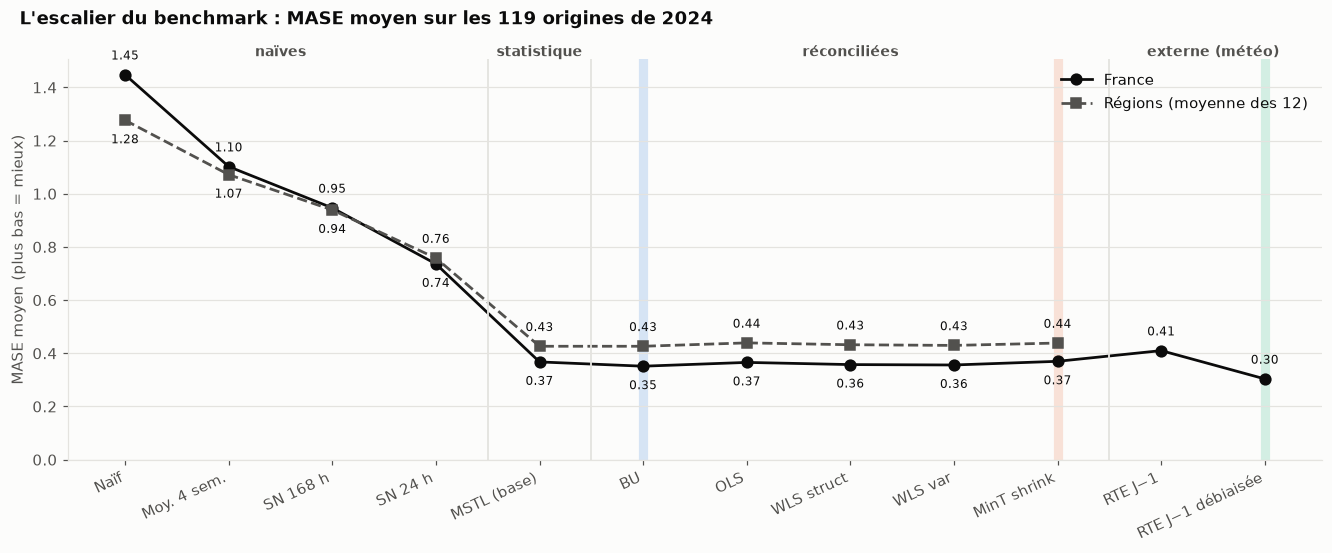

In [3]:
groups = {"naïves": NAIVES, "statistique": ["base"], "réconciliées": RECONCILED, "externe (météo)": EXTERNAL}
fig = figures.ladder(bl, [*NAIVES, "base", *RECONCILED, *EXTERNAL], groups,
                     "L'escalier du benchmark : MASE moyen sur les 119 origines de 2024")
export(fig, "benchmark_escalier"); plt.show()

**Lecture de l'escalier.** On lit la courbe de gauche à droite, du plus simple au plus élaboré :

1. **Les baselines naïves s'améliorent à chaque marche** : 1,45 → 1,10 → 0,95 → 0,74 au niveau France.
   La meilleure est la veille (SN 24 h), pas la semaine précédente : en 2024, la consommation dérive assez
   d'une semaine à l'autre pour que la saisonnalité hebdomadaire seule soit trompeuse.
2. **La grande marche est le modèle statistique** : MSTL divise l'erreur du naïf saisonnier par 2,6 au
   niveau France (gain de 61 %) et par 2,2 en région (55 %).
3. **Les réconciliations forment un plateau** : entre 0,352 et 0,370 au niveau France, entre 0,427 et 0,439
   en région. Le bottom-up est le point bas du plateau, aux deux niveaux. La réconciliation déplace l'erreur
   de quelques pourcents ; le modèle de base l'avait déplacée de 60 %.
4. **RTE J−1 débiaisée est la seule solution sous le plateau** : 0,304, soit 13,6 % de mieux que le
   bottom-up. Telle que publiée, à cause de son biais, elle fait 16,7 % de moins bien.

**Exemple.** Au niveau France, passer du naïf saisonnier à MSTL fait gagner 61 % ; passer de MSTL au
bottom-up, 4,4 % ; passer de MSTL à MinT shrink, en perdre 0,6 %. Ajouter la météo (RTE débiaisée) ferait
gagner 17 % de plus que MSTL.

**À retenir.** La troisième conclusion du bloc est confirmée de façon nette : le levier est le modèle de base
et l'information qu'il reçoit (la météo), pas le choix de la réconciliation.

### Point d'attention : la moyenne des gains par origine peut mentir

Le chiffre clé des notebooks 03 et 04 est une **moyenne de variations par origine**. Pour le benchmark, on
utilise le **gain agrégé** : 1 − MASE moyen de la méthode / MASE moyen de la référence. Il se relit
directement dans le tableau. Les deux mesures s'accordent quand les méthodes sont proches ; elles divergent
quand elles sont très différentes.

In [4]:
per_origin = bm.gain(bl, "BU").groupby(["level", "method"])["gain"].mean()
agg = bm.aggregate_gain(bl, "BU").set_index(["level", "method"])["gain"]
cmp_ = pd.DataFrame({"gain agrégé": agg, "moyenne des gains par origine": per_origin}).loc["France"]
display((cmp_.loc[["MinT shrink", "WLS var", "SN 24 h", "RTE J-1 débiaisée"]] * 100).style.format("{:+.1f} %"))

,gain agrégé,moyenne des gains par origine
method,,
MinT shrink,-5.2 %,-5.3 %
WLS var,-1.3 %,-0.8 %
SN 24 h,-109.4 %,-233.4 %
RTE J-1 débiaisée,+13.6 %,-51.6 %


**Lecture.** Pour MinT shrink et WLS var, les deux mesures donnent le même signe et le même ordre de grandeur.
Pour RTE débiaisée, elles se contredisent : +13,6 % de gain agrégé, mais −51,6 % en moyenne par origine. La
raison : les jours calmes, le bottom-up fait une erreur minuscule, et le rapport des deux MASE explose même si
RTE se trompe de peu en mégawatts. Quelques jours faciles dominent alors la moyenne. **Pour comparer des
méthodes très différentes, on compare des moyennes d'erreurs, pas des moyennes de rapports.**

## 3. Le gain dépend-il de l'heure prévue ?

Chaque prévision couvre les 24 heures du jour J, de 00:00 à 23:00 UTC. On calcule le MASE heure par heure
(la moyenne des 24 courbes redonne exactement le MASE du tableau).

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


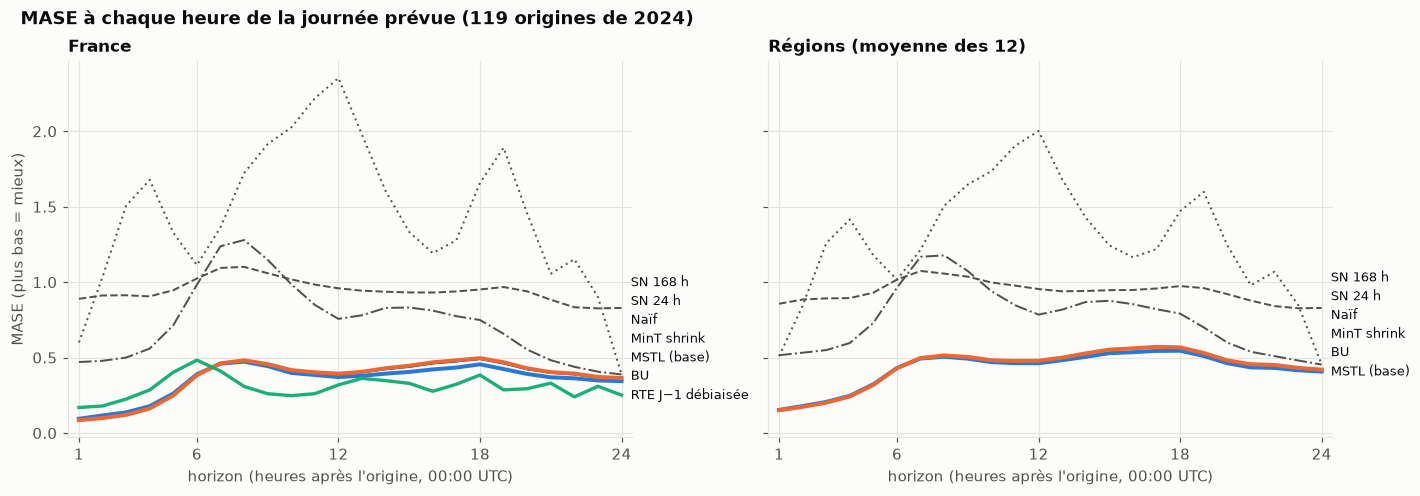

In [5]:
h = bm.mase_by_horizon(fc, scales, hier)
fig = figures.horizon_curves(h, ["Naïf", "SN 24 h", "SN", "base", "BU", "MinT shrink", "RTE J-1 débiaisée"],
                             "MASE à chaque heure de la journée prévue (119 origines de 2024)")
export(fig, "benchmark_horizon"); plt.show()

**Lecture.** Les baselines naïves (en gris) ont une erreur qui suit la journée : faible la nuit, forte au
lever (6-8 h) et en fin de journée (18-19 h), quand la consommation change vite. Le naïf (pointillé fin)
n'est bon que juste après l'origine. MSTL, BU et MinT partent bas (MASE ≈ 0,1 à h = 1) et montent à 0,4-0,5 en
journée. RTE débiaisée suit un autre profil : **plus mauvaise que MSTL les 6 premières heures, meilleure
ensuite**. La mémoire des dernières valeurs s'use avec l'horizon ; la météo prévue, elle, ne s'use pas sur
24 heures.

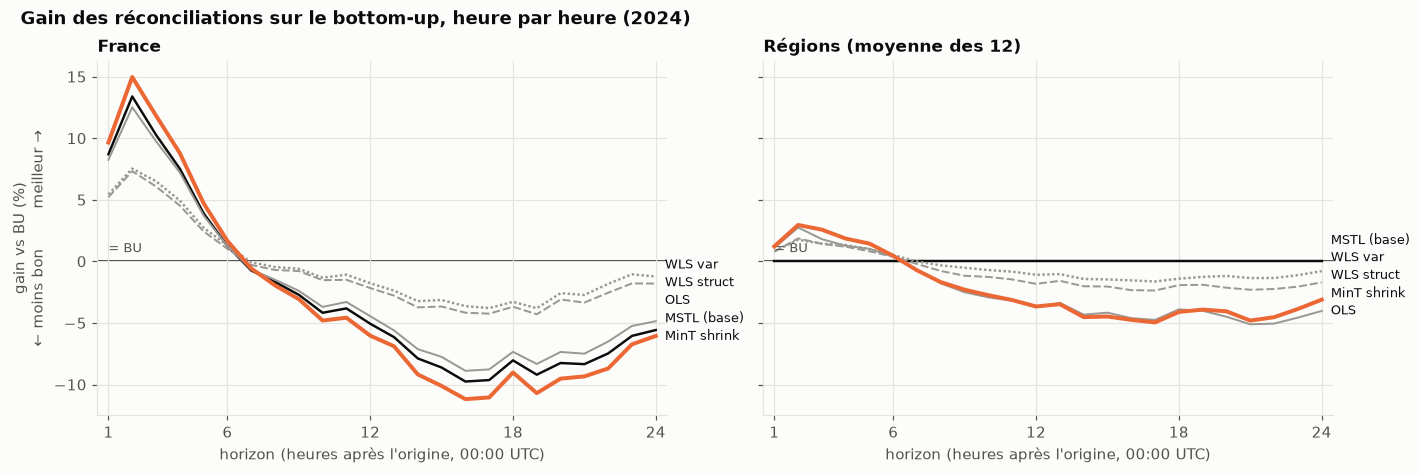

gain vs BU (%), moyenne sur les heures 1-6 puis 7-24 :


method         base  OLS  WLS var  MinT shrink
level                                         
France  False  -6.3 -5.6     -2.1         -7.2
        True    7.5  7.1      4.7          8.6
Régions False   0.0 -3.7     -1.1         -3.6
        True    0.0  1.4      1.1          1.7

In [6]:
gh = bm.gain_by_horizon(h, "BU")
fig = figures.gain_curves(gh, "horizon", ["base", *RECONCILED], "BU",
                          "Gain des réconciliations sur le bottom-up, heure par heure (2024)",
                          "horizon (heures après l'origine, 00:00 UTC)")
for ax in fig.axes:
    ax.set_xticks([1, 6, 12, 18, 24])
export(fig, "benchmark_gain_horizon"); plt.show()
w = gh.pivot_table(index=["level", "horizon"], columns="method", values="gain")
print("gain vs BU (%), moyenne sur les heures 1-6 puis 7-24 :")
display((w.groupby([w.index.get_level_values("level"), w.index.get_level_values("horizon") <= 6])
         .mean()[["base", "OLS", "WLS var", "MinT shrink"]] * 100).round(1))

**C'est le résultat le plus nouveau de ce notebook.** Le classement entre réconciliations **s'inverse au cours
de la journée** :

- **Heures 1 à 6** : au niveau France, la prévision MSTL directe du total et MinT shrink battent le bottom-up
  de 7,5 % et 8,6 % en moyenne. En région, MinT gagne aussi un peu (+1,7 %).
- **Heures 7 à 24** : le bottom-up reprend l'avantage, de 6 à 7 % au niveau France, et MinT perd 3,6 % en région.

**Intuition.** Juste après l'origine, la prévision directe du total s'appuie sur la dernière valeur connue
du total, très informative, et MinT donne du poids à cette prévision. Plus loin, la prévision du total
dérive, alors que la somme de 12 prévisions régionales compense une partie de leurs erreurs. Les journées
comptent 6 heures « favorables » et 18 « défavorables » : le bottom-up gagne en moyenne.

**Point d'attention.** Cela ne remet pas en cause la recommandation pour une prévision J sur 24 h, mais cela
montre qu'elle dépend de l'horizon : pour une prévision infra-journalière (h ≤ 6), la conclusion serait
différente. C'est une **nuance**, pas une contradiction.

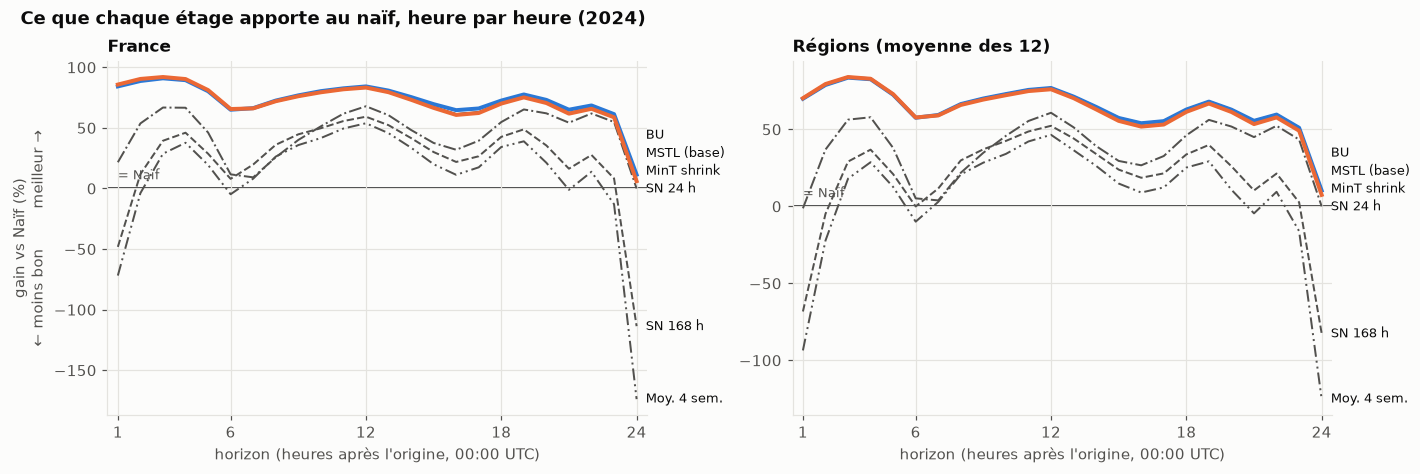

In [7]:
gn = bm.gain_by_horizon(h, "Naïf")
fig = figures.gain_curves(gn, "horizon", ["SN 24 h", "SN", "Moy. 4 sem.", "base", "BU", "MinT shrink"], "Naïf",
                          "Ce que chaque étage apporte au naïf, heure par heure (2024)",
                          "horizon (heures après l'origine, 00:00 UTC)", sharey=False)
for ax in fig.axes:
    ax.set_xticks([1, 6, 12, 18, 24])
export(fig, "benchmark_gain_naif_horizon"); plt.show()

**Lecture.** La même information, vue depuis le naïf. Le modèle statistique apporte 50 à 90 % de gain de
h = 1 à h = 23 ; les réconciliations (BU, MinT) se superposent à MSTL : à cette échelle, on ne les distingue
pas. Les naïfs saisonniers perdent face au naïf dans les toutes premières heures (la dernière valeur est alors
la meilleure information) et à h = 24 : la « dernière valeur connue », 23 h la veille, tombe alors exactement
24 heures avant la cible, comme SN 24 h.

## 4. Le gain dépend-il de la saison ?

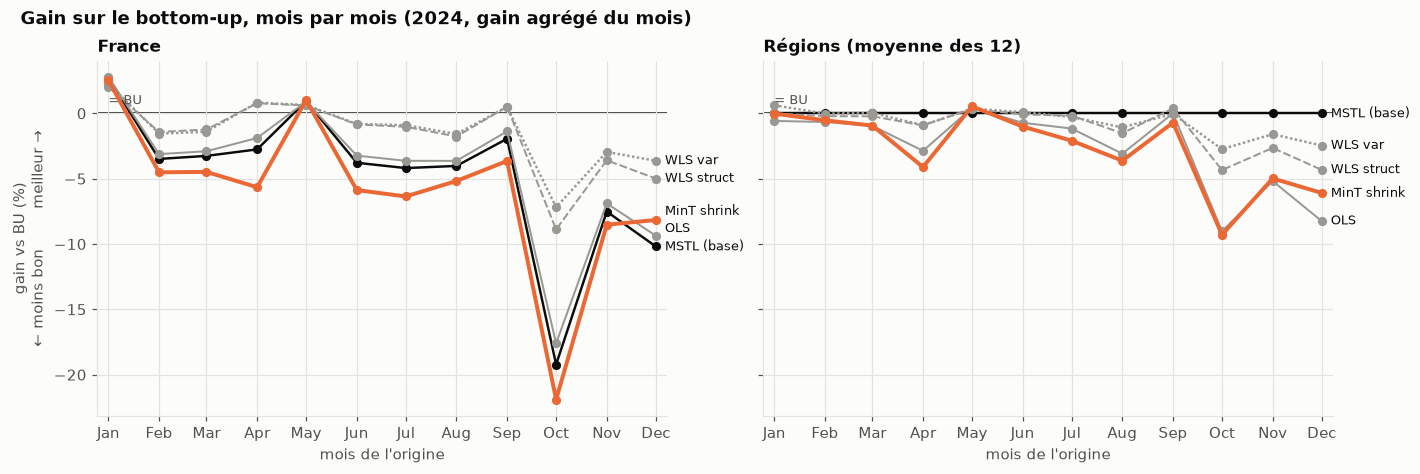

mois où MinT shrink bat BU (Régions) : 1 sur 12
mois où BU bat la base MSTL (France) : 10 sur 12


In [8]:
mon = bm.monthly(bl)
mw = mon.pivot_table(index=["level", "month"], columns="method", values="mase")
gm = (1 - mw.div(mw["BU"], axis=0)).stack().rename("gain").reset_index()
fig = figures.gain_curves(gm, "month", ["base", *RECONCILED], "BU",
                          "Gain sur le bottom-up, mois par mois (2024, gain agrégé du mois)", "mois de l'origine",
                          markers=True)
for ax in fig.axes:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
export(fig, "benchmark_gain_mois"); plt.show()
ms = mon.pivot_table(index="month", columns=["level", "method"], values="mase")
print("mois où MinT shrink bat BU (Régions) :",
      int((ms[("Régions", "MinT shrink")] < ms[("Régions", "BU")]).sum()), "sur 12")
print("mois où BU bat la base MSTL (France) :",
      int((ms[("France", "BU")] < ms[("France", "base")]).sum()), "sur 12")

**Lecture.**

- **Au niveau France, le bottom-up bat la prévision MSTL directe 10 mois sur 12.** Le décrochage d'octobre
  (−19 % pour MSTL, −22 % pour MinT) vient surtout du 29 octobre, à l'approche de la Toussaint, où toutes les
  prévisions se trompent fortement : la somme des régions y limite les dégâts.
- **En région, MinT shrink ne bat le bottom-up qu'un mois sur 12** (mai, de 0,5 %). L'écart est faible au
  printemps et en été, net à l'automne.
- Les méthodes à W diagonale (WLS) restent toujours les plus proches du bottom-up.

**À retenir.** La perte de MinT shrink n'est pas l'effet d'une saison particulière : elle est présente presque
tous les mois, avec une ampleur qui varie.

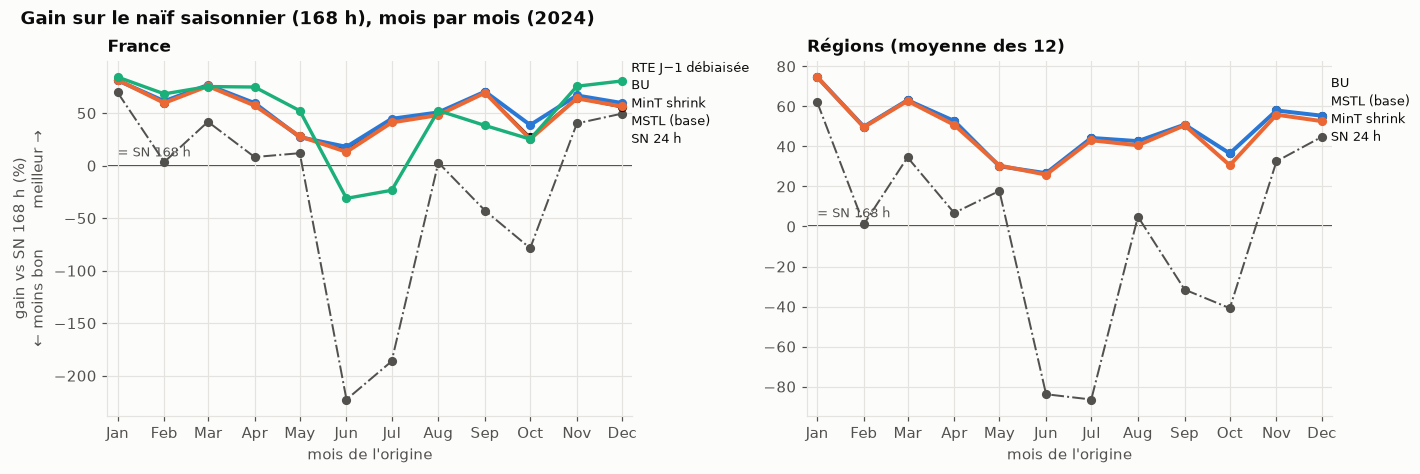

In [9]:
gsn = (1 - mw.div(mw["SN"], axis=0)).stack().rename("gain").reset_index()
fig = figures.gain_curves(gsn, "month", ["SN 24 h", "base", "BU", "MinT shrink", "RTE J-1 débiaisée"], "SN",
                          "Gain sur le naïf saisonnier (168 h), mois par mois (2024)", "mois de l'origine",
                          markers=True, sharey=False)
for ax in fig.axes:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
export(fig, "benchmark_gain_sn_mois"); plt.show()

**Lecture.** Le gain sur le naïf saisonnier, lui, dépend beaucoup de la saison : de 75-80 % en janvier à un
minimum en juin (15 à 25 %), quand la consommation est basse et régulière et que le naïf saisonnier est déjà
bon. SN 24 h fait bien moins bien que SN 168 h en juin-juillet et à l'automne : la veille prévoit mal les
week-ends. RTE débiaisée perd sa supériorité en juin-juillet : son biais d'été n'est pas son biais moyen de
l'année écoulée, et la correction tombe à faux.

## 5. Le classement dépend-il de la métrique ?

Le MASE divise l'erreur par celle du naïf saisonnier. Une conclusion solide doit tenir en mégawatts (MAE),
en pénalisant les grosses erreurs (RMSE) et en pourcentage (MAPE).

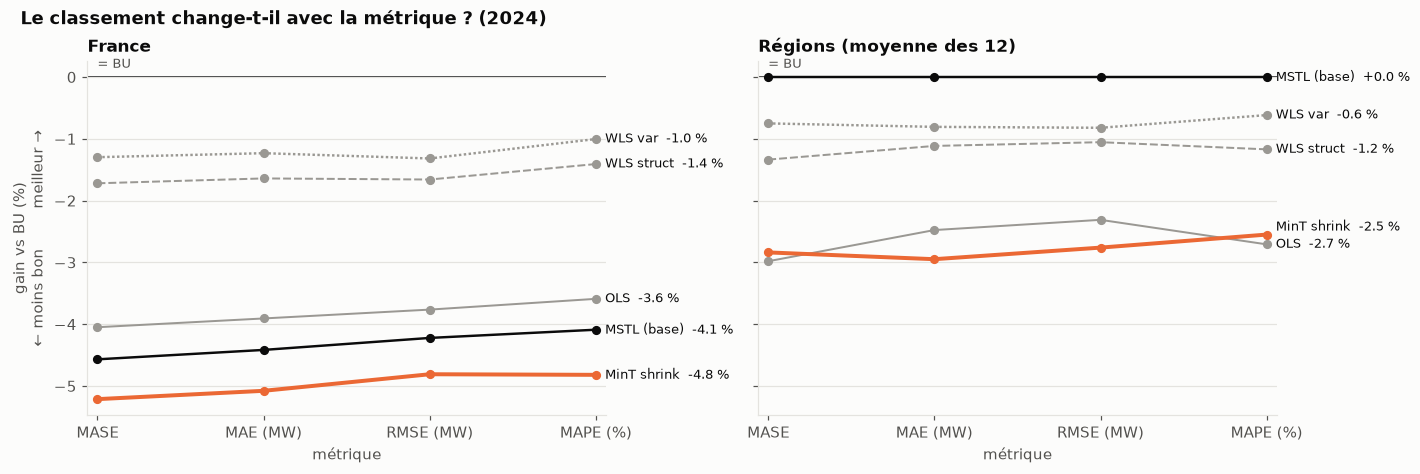

level       France                             Régions                     \
metric        MASE MAE (MW) RMSE (MW) MAPE (%)    MASE MAE (MW) RMSE (MW)   
method                                                                      
base          -4.6     -4.4      -4.2     -4.1     0.0      0.0       0.0   
OLS           -4.0     -3.9      -3.8     -3.6    -3.0     -2.5      -2.3   
WLS struct    -1.7     -1.6      -1.7     -1.4    -1.3     -1.1      -1.1   
WLS var       -1.3     -1.2      -1.3     -1.0    -0.8     -0.8      -0.8   
MinT shrink   -5.2     -5.1      -4.8     -4.8    -2.8     -2.9      -2.8   

level                 
metric      MAPE (%)  
method                
base             0.0  
OLS             -2.7  
WLS struct      -1.2  
WLS var         -0.6  
MinT shrink     -2.5

In [10]:
em = bm.error_metrics(fc, hier, scales)
gmet = bm.gain_by_metric(em, "BU")
gmet["metric"] = pd.Categorical(gmet["metric"], ["MASE", "MAE (MW)", "RMSE (MW)", "MAPE (%)"], ordered=True)
fig = figures.gain_curves(gmet, "metric", ["base", *RECONCILED], "BU",
                          "Le classement change-t-il avec la métrique ? (2024)", "métrique",
                          markers=True, xticks="categorical", end_values=True)
export(fig, "benchmark_metriques"); plt.show()
display((gmet.pivot_table(index="method", columns=["level", "metric"], values="gain").loc[
    ["base", *RECONCILED[1:]]] * 100).round(1))

**Lecture.** Les courbes sont presque plates : **le classement est le même avec les quatre métriques**. Au
niveau France, MinT shrink reste la moins bonne réconciliation (−4,8 % à −5,2 %) et WLS var la plus proche du
bottom-up ; en région, MinT shrink et OLS perdent 2,3 à 3,0 % quelle que soit la métrique.

**À retenir.** Le résultat ne vient pas d'un choix d'évaluation : il est le même en MW, en %, avec ou sans
pénalité des grosses erreurs.

## 6. Combien d'origines faut-il pour conclure ?

Le protocole principal (4 origines) donnait MinT shrink gagnant ; 119 origines le donnent perdant. On rejoue le
calcul en ajoutant les origines une à une : dans l'ordre chronologique (ce qu'aurait vu un analyste au fil de
l'année), et dans 200 ordres aléatoires (la bande grise contient 90 % des tirages).

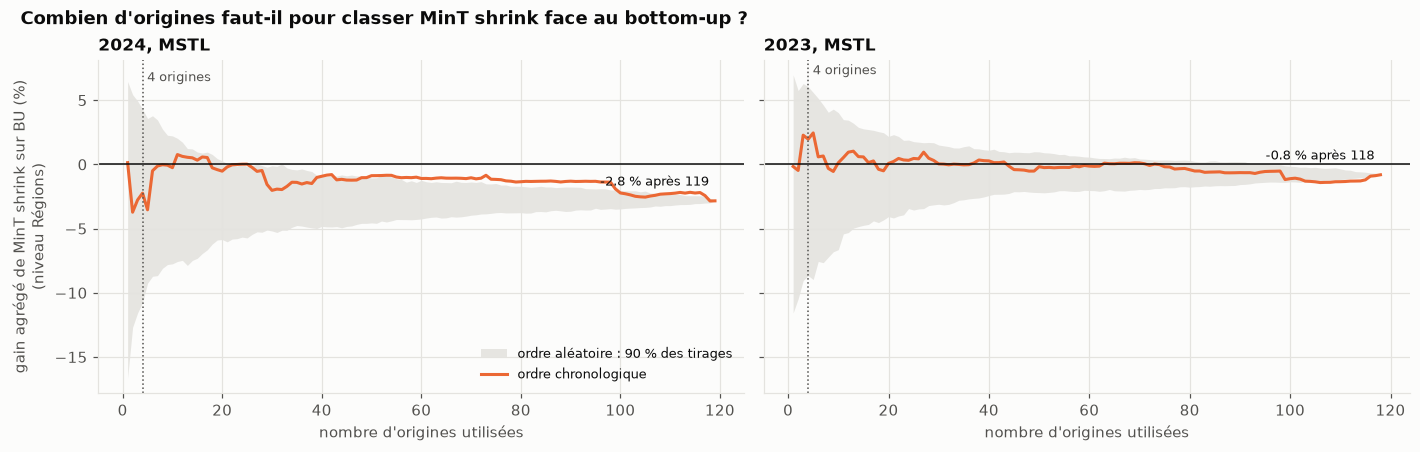

2024, MSTL : avec   4 origines tirées au hasard, 90 % des gains entre -10.8% et +4.3%
2024, MSTL : avec  10 origines tirées au hasard, 90 % des gains entre -7.7% et +2.2%
2024, MSTL : avec  30 origines tirées au hasard, 90 % des gains entre -5.2% et -0.1%
2024, MSTL : avec  60 origines tirées au hasard, 90 % des gains entre -4.2% et -1.2%
2024, MSTL : la bande passe sous 0 à partir de k = 22
2023, MSTL : avec   4 origines tirées au hasard, 90 % des gains entre -8.7% et +6.0%
2023, MSTL : avec  10 origines tirées au hasard, 90 % des gains entre -6.6% et +4.0%
2023, MSTL : avec  30 origines tirées au hasard, 90 % des gains entre -3.1% et +1.5%
2023, MSTL : avec  60 origines tirées au hasard, 90 % des gains entre -2.0% et +0.6%
2023, MSTL : la bande passe sous 0 à partir de k = 96


In [11]:
conv = {STUDIES[w]: bm.convergence(data[w][2], "MinT shrink", "BU") for w in ["robustness", "annee_2023"]}
fig = figures.convergence_plot(conv, "Combien d'origines faut-il pour classer MinT shrink face au bottom-up ?",
                               "gain agrégé de MinT shrink sur BU (%)\n(niveau Régions)")
export(fig, "benchmark_convergence"); plt.show()
for name, c in conv.items():
    for k in (4, 10, 30, 60):
        print(f"{name} : avec {k:3d} origines tirées au hasard, 90 % des gains entre "
              f"{c['p05'].iat[k - 1]:+.1%} et {c['p95'].iat[k - 1]:+.1%}")
    neg = c.index[(c["p95"] < 0)]
    print(f"{name} : la bande passe sous 0 à partir de k = {int(c['k'].iat[neg[0]]) if len(neg) else 'jamais'}")

**Lecture.**

- **Avec 4 origines, tout est possible** : en 2024, le gain de MinT shrink sur BU est quelque part entre
  −10,8 % et +4,3 % ; en 2023, entre −8,7 % et +6,0 %. Le protocole principal ne pouvait pas trancher.
- **En 2024, la bande passe entièrement sous zéro à partir de 22 origines** : au-delà, n'importe quel
  échantillon d'origines donne MinT perdant.
- **En 2023, il faut 96 origines** : l'écart est plus petit (−0,8 %), il faut beaucoup plus d'origines pour
  le distinguer de zéro.

**À retenir.** Le nombre d'origines nécessaire dépend de la taille de l'effet. Pour un écart de quelques
pourcents entre méthodes, il faut **plusieurs dizaines d'origines**, pas 4.

## 7. Confirmation 1 : une autre année (2023)

Même protocole, mêmes modèles, mêmes réglages : seule l'année change. 118 origines, une tous les 3 jours, de
janvier à décembre 2023. Le backtest est indépendant de celui de 2024 (`uv run w37 eco2mix backtest --which
annee_2023`).

In [12]:
fc23, sc23, bl23 = data["annee_2023"]
t23 = metrics.summary_table(bl23, order)
t23.index = pretty(t23.index)
display(t23.style.format("{:.3f}", na_rep="").set_caption("2023 : MASE moyen et écart-type (118 origines)"))
display(bm.paired_vs_reference(bl23, ["base", "OLS", "WLS struct", "WLS var", "MinT shrink"]).style
        .format({"gain": "{:+.2%}", "origines gagnées": "{:.0%}", "p Wilcoxon (Holm)": "{:.3f}",
                 "p HAC (Holm)": "{:.3f}"}).set_caption("2023 : chaque méthode contre le bottom-up"))

,France mean,France std,Régions mean,Régions std
Naïf,1.391,0.483,1.255,0.351
Moy. 4 sem.,1.136,1.130,1.087,0.895
SN 168 h,0.944,0.937,0.951,0.735
SN 24 h,0.699,0.620,0.738,0.490
MSTL (base),0.317,0.238,0.418,0.184
BU,0.314,0.236,0.418,0.184
OLS,0.317,0.237,0.423,0.184
WLS struct,0.313,0.235,0.419,0.182
WLS var,0.314,0.235,0.419,0.183
MinT shrink,0.319,0.239,0.422,0.185


**Lecture.**

- **L'escalier est le même** : naïf ≫ SN 168 h > SN 24 h ≫ MSTL ≈ réconciliations > RTE débiaisée.
- **Le bottom-up reste au plateau bas** : MinT shrink perd encore aux deux niveaux (−0,8 % en région,
  −1,5 % au niveau France), et ne gagne qu'à 43-47 % des origines.
- **Mais les écarts sont trois fois plus petits qu'en 2024, et aucun n'est significatif** (p = 1 après Holm).
  WLS struct fait même jeu égal avec le bottom-up au niveau France (+0,1 %).
- RTE débiaisée reste devant tout le monde (0,277 contre 0,314 pour BU).

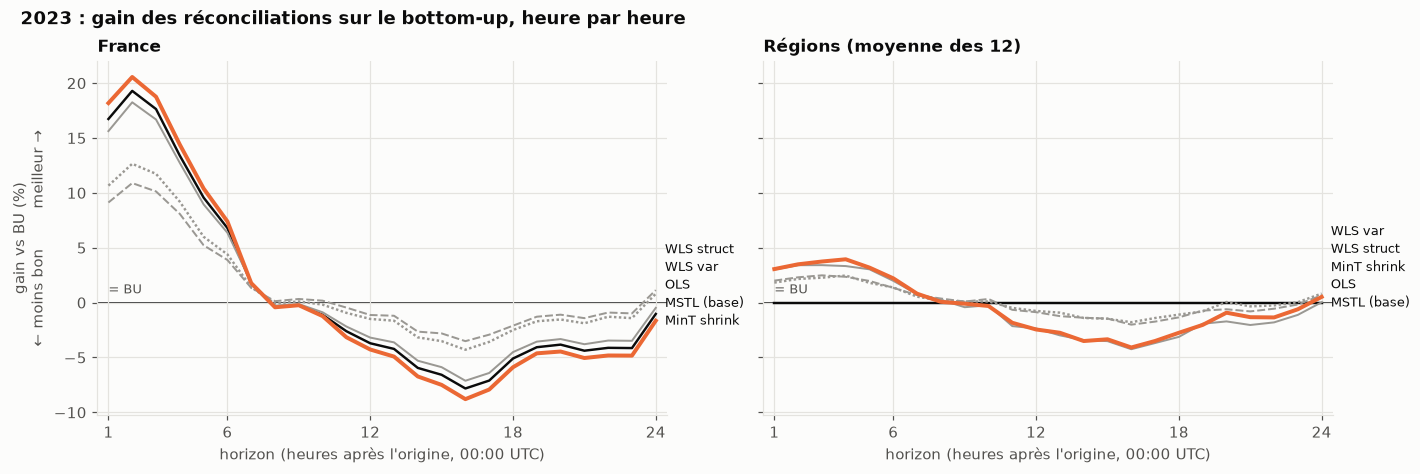

In [13]:
h23 = bm.mase_by_horizon(fc23, sc23, hier)
fig = figures.gain_curves(bm.gain_by_horizon(h23, "BU"), "horizon", ["base", *RECONCILED], "BU",
                          "2023 : gain des réconciliations sur le bottom-up, heure par heure",
                          "horizon (heures après l'origine, 00:00 UTC)")
for ax in fig.axes:
    ax.set_xticks([1, 6, 12, 18, 24])
export(fig, "confirmation_2023_horizon"); plt.show()

**Lecture.** Le profil par horizon de 2024 se retrouve en 2023, plus marqué encore au début : MinT bat le
bottom-up de 18 à 20 % sur les 3 premières heures au niveau France (3 à 4 % en région), puis perd jusqu'à 9 %
l'après-midi. Ce n'est donc pas un hasard de 2024.

**À retenir.** 2023 confirme le **sens** de toutes les conclusions (bottom-up au moins aussi bon que toute
autre réconciliation, MinT shrink jamais devant), mais pas leur **ampleur** : en 2023, choisir entre BU, WLS et
MinT ne change presque rien. La recommandation « livrer le bottom-up » en sort renforcée (il ne perd jamais),
l'argument « MinT shrink dégrade nettement » en sort affaibli.

## 8. Confirmation 2 : un autre modèle de base (AutoETS)

L'explication du bloc dit que MinT shrink perd **à cause des résidus in-sample de MSTL** : MSTL est une
décomposition par lissage, qui regarde le passé *et le futur* de chaque instant ; ses résidus sont des restes,
pas des erreurs de prévision. Si c'est vrai, l'explication fait une **prédiction testable** : avec un modèle dont
les résidus in-sample sont de vraies erreurs de prévision à un pas, le handicap de MinT doit disparaître.

On refait donc l'année 2024 avec **AutoETS** (lissage exponentiel, saisonnalité 24 h) à la place de MSTL. ETS est
un *filtre* : son ajustement à l'instant t n'utilise que le passé, ses résidus sont des erreurs à un pas. Tout le
reste est identique (`uv run w37 eco2mix backtest --which ets_2024`).

**Point d'attention.** AutoETS ne modélise que la saisonnalité journalière : il ignore la semaine, et sera
donc un modèle de base nettement moins bon que MSTL. Ce n'est pas un défaut de l'expérience : on ne cherche pas
le meilleur modèle, on teste le mécanisme.

In [14]:
fce, sce, ble = data["ets_2024"]
te = metrics.summary_table(ble, order)
te.index = pretty(te.index, "AutoETS (base)")
display(te.style.format("{:.3f}", na_rep="").set_caption("2024, modèle de base AutoETS : MASE moyen et écart-type"))
display(bm.paired_vs_reference(ble, ["base", "OLS", "WLS struct", "WLS var", "MinT shrink"]).style
        .format({"gain": "{:+.2%}", "origines gagnées": "{:.0%}", "p Wilcoxon (Holm)": "{:.3f}",
                 "p HAC (Holm)": "{:.3f}"}).set_caption("AutoETS : chaque méthode contre le bottom-up"))
diag_e = run.load_results(paths, "ets_2024")["diagnostics"]
diag_m = run.load_results(paths, "robustness")["diagnostics"]
print(f"λ médian : MSTL {diag_m['lambda'].median():.4f} ; AutoETS {diag_e['lambda'].median():.4f}")
print(f"cond(W) médian : MSTL {diag_m['cond_W'].median():.0f} ; AutoETS {diag_e['cond_W'].median():.0f}")

,France mean,France std,Régions mean,Régions std
Naïf,1.448,0.454,1.276,0.347
Moy. 4 sem.,1.102,1.087,1.072,0.871
SN 168 h,0.947,0.996,0.939,0.812
SN 24 h,0.736,0.554,0.758,0.462
AutoETS (base),0.639,0.386,0.671,0.319
BU,0.652,0.369,0.671,0.319
OLS,0.640,0.385,0.667,0.326
WLS struct,0.645,0.377,0.667,0.323
WLS var,0.650,0.371,0.670,0.320
MinT shrink,0.655,0.367,0.671,0.317


λ médian : MSTL 0.0180 ; AutoETS 0.0019
cond(W) médian : MSTL 146 ; AutoETS 1189


**Lecture.**

- **AutoETS est un modèle de base bien plus faible** : MASE 0,64 au niveau France contre 0,37 pour MSTL, soit
  31 % de gain sur le naïf saisonnier au lieu de 61 %. Il reste meilleur que toutes les baselines naïves.
- **Le handicap de MinT shrink disparaît** : −0,0 % en région, −0,5 % au niveau France, il gagne à une origine
  sur deux en région, et rien n'est significatif. La prédiction de l'explication est vérifiée.
- **Le bottom-up n'est plus le meilleur** : OLS et WLS struct font +0,5 % en région, et la prévision AutoETS
  directe du total fait +1,9 % au niveau France. Ces écarts ne sont **pas significatifs** (p ≥ 0,17 après Holm).
- W est beaucoup plus mal conditionnée avec AutoETS (cond(W) médian ≈ 1 200 contre ≈ 150), parce que ses
  résidus sont fortement corrélés entre régions : c'est justement ce qu'on veut que W voie.

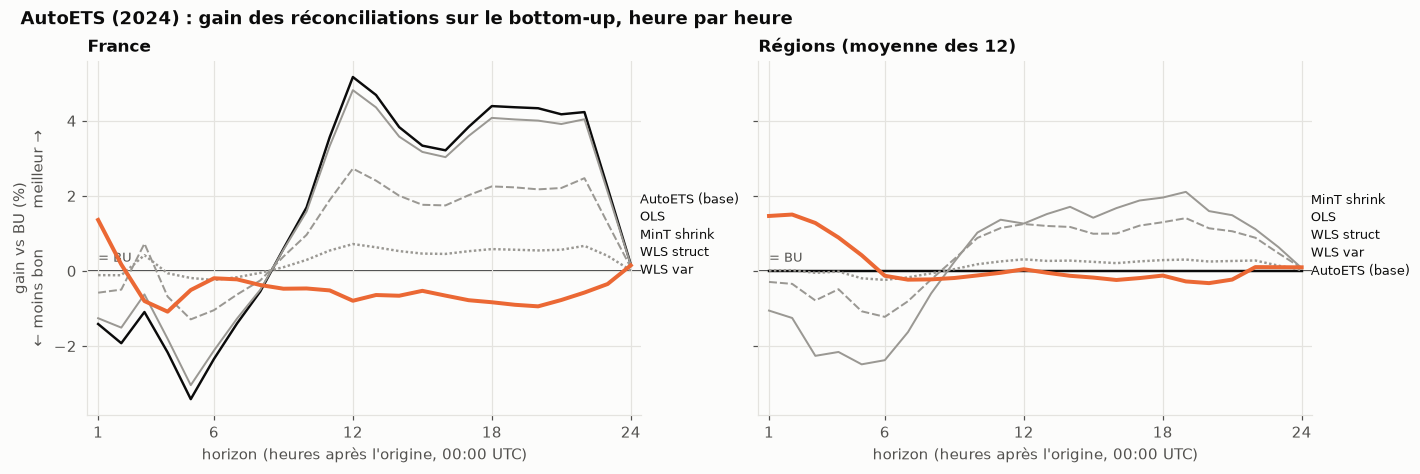

In [15]:
he = bm.mase_by_horizon(fce, sce, hier)
fig = figures.gain_curves(bm.gain_by_horizon(he, "BU"), "horizon", ["base", *RECONCILED], "BU",
                          "AutoETS (2024) : gain des réconciliations sur le bottom-up, heure par heure",
                          "horizon (heures après l'origine, 00:00 UTC)", base_label="AutoETS (base)")
for ax in fig.axes:
    ax.set_xticks([1, 6, 12, 18, 24])
export(fig, "confirmation_ets_horizon"); plt.show()

**Lecture.** Le profil par horizon **n'est pas celui de MSTL** : avec AutoETS, la prévision directe du total
perd les premières heures et gagne l'après-midi (+3 à +5 % au niveau France), et MinT shrink reste à 1,5 % au plus
du bottom-up, à toutes les heures. L'avantage des premières heures vu en 2023 et 2024 est donc propre à MSTL,
pas à la réconciliation.

La mesure directe du mécanisme : la corrélation moyenne entre régions des résidus in-sample (ce que voit W),
comparée à celle des vraies erreurs hors échantillon (ce que W devrait décrire). Les résidus in-sample sont
recalculés à 4 origines (les 4 mardis de novembre), en réentraînant les deux modèles, ≈ 30 s.

In [16]:
from w37_reconciliation.eco2mix.backtest import BacktestSpec
rows = {}
for which, name in [("robustness", "MSTL"), ("ets_2024", "AutoETS")]:
    spec = BacktestSpec.from_config(cfg, which)
    ins = [bm.mean_region_correlation(bm.insample_residuals(hier, pd.Timestamp(o), spec).to_numpy())
           for o in cfg["backtest"]["main_origins"]]
    oos = bm.mean_region_correlation(bm.oos_errors(data[which][0], hier.order).to_numpy())
    rows[name] = {"in-sample (min, 4 origines)": min(ins), "in-sample (max)": max(ins),
                  "hors échantillon (119 origines)": oos}
display(pd.DataFrame(rows).T.style.format("{:.2f}")
        .set_caption("Corrélation moyenne entre régions : ce que voit W, et la réalité"))

,"in-sample (min, 4 origines)",in-sample (max),hors échantillon (119 origines)
MSTL,0.11,0.13,0.56
AutoETS,0.49,0.57,0.66


**Lecture.** C'est la preuve la plus directe du bloc :

| Modèle | Corrélation in-sample (ce que voit W) | Corrélation réelle | MinT shrink vs BU (régions) |
|---|---|---|---|
| MSTL | 0,11 à 0,13 | 0,56 | **−2,8 %** |
| AutoETS | 0,49 à 0,57 | 0,66 | **−0,0 %** |

Quand W voit des corrélations proches de la réalité (AutoETS), MinT shrink ne perd plus rien. Quand elle voit
des régions presque indépendantes alors qu'elles se trompent ensemble (MSTL), MinT répartit mal les corrections
et perd.

**À retenir.** La cause identifiée au notebook 04 est confirmée par une deuxième expérience, indépendante de la
première : le problème n'est pas MinT, c'est l'estimation de W sur des résidus qui ne sont pas des erreurs de
prévision. Le corollaire est aussi confirmé : avec un bon W, MinT ne fait pas mieux que le bottom-up ici.

## 9. Confirmation 3 : la cause, W

Le notebook 04 a montré, sur 2024, qu'en estimant W sur les **erreurs hors échantillon des origines passées**
(strictement antérieures, sans fuite) au lieu des résidus in-sample, MinT revient au niveau du bottom-up. On
rejoue l'expérience sur les deux années, avec le même test apparié pour toutes les lignes.

In [17]:
for which in ["robustness", "annee_2023"]:
    f, sc, _ = data[which]
    rec = reconcile_with_past_errors(f, hier, min_past_origins=20)
    display(bm.paired_vs_reference(bm.by_level(rec, sc, hier), ["MinT shrink", "MinT oos", "WLS var", "WLS var oos"])
            .style.format({"gain": "{:+.2%}", "origines gagnées": "{:.0%}", "p Wilcoxon (Holm)": "{:.3f}",
                           "p HAC (Holm)": "{:.3f}"})
            .set_caption(f"{STUDIES[which]}, {rec['origin'].nunique()} origines : W in-sample contre W hors "
                         "échantillon, face au bottom-up"))

**Lecture.**

- **2024** (99 origines) : avec W in-sample, MinT shrink perd 3,5 % en région et 6,0 % au niveau France. Avec
  W hors échantillon, il passe à +1,0 % et +1,1 %, à égalité statistique avec le bottom-up (p ≈ 0,8, une
  origine sur deux gagnée).
- **2023** (98 origines) : même mouvement, en plus petit. MinT shrink perd 1,0 % et 2,5 % ; MinT avec W hors
  échantillon ne perd plus que 0,3 %.
- Les deux fois, **changer W, et seulement W, efface l'essentiel du handicap**. C'est l'expérience contrôlée
  qui identifie la cause, et elle se reproduit sur une autre année.

**Point d'attention.** Le gain agrégé de +1 % en 2024 n'autorise pas à dire que « MinT bien estimé bat le
bottom-up » : le test ne distingue pas cet écart de zéro, et 2023 donne −0,3 %.

Combien d'erreurs passées faut-il pour estimer W ? On restreint W aux k dernières origines terminées.

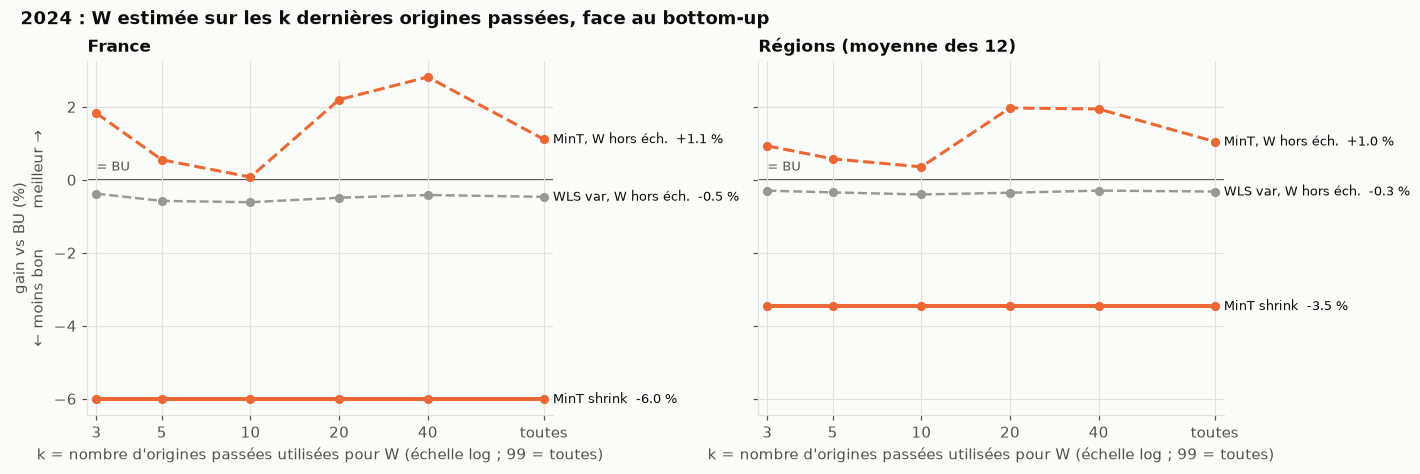

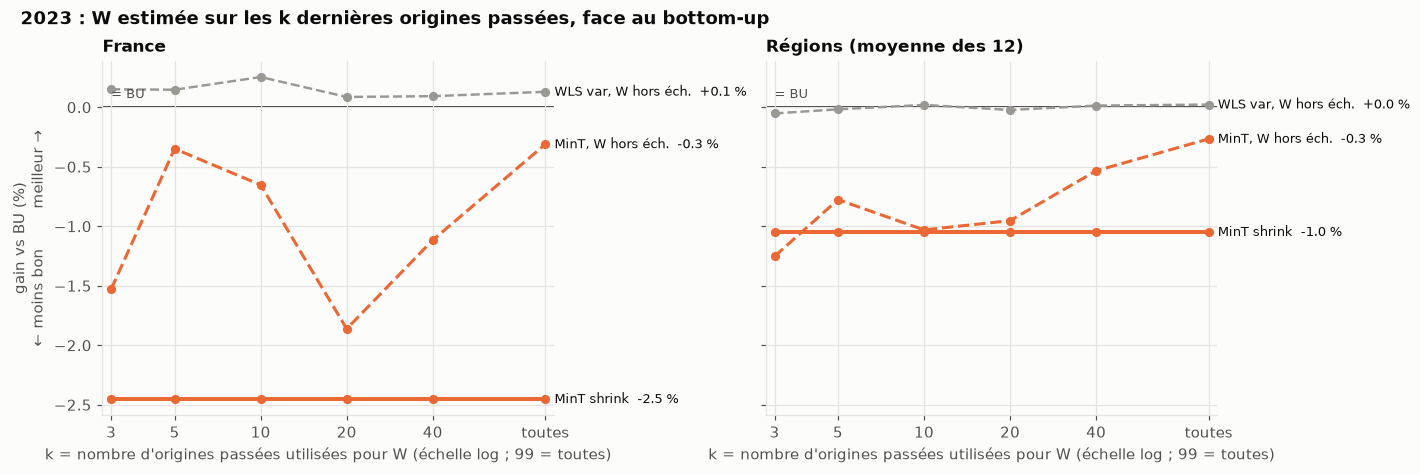

level             France                          Régions                      \
window                3    5    10   20   40   99      3    5    10   20   40   
study method                                                                    
2023  MinT oos      -1.5 -0.3 -0.7 -1.9 -1.1 -0.3    -1.3 -0.8 -1.0 -1.0 -0.5   
      MinT shrink   -2.5 -2.5 -2.5 -2.5 -2.5 -2.5    -1.0 -1.0 -1.0 -1.0 -1.0   
      WLS var oos    0.2  0.1  0.3  0.1  0.1  0.1    -0.1 -0.0  0.0 -0.0  0.0   
2024  MinT oos       1.8  0.5  0.1  2.2  2.8  1.1     0.9  0.6  0.4  2.0  1.9   
      MinT shrink   -6.0 -6.0 -6.0 -6.0 -6.0 -6.0    -3.5 -3.5 -3.5 -3.5 -3.5   
      WLS var oos   -0.4 -0.6 -0.6 -0.5 -0.4 -0.5    -0.3 -0.3 -0.4 -0.4 -0.3   

level                   
window              99  
study method            
2023  MinT oos    -0.3  
      MinT shrink -1.0  
      WLS var oos  0.0  
2024  MinT oos     1.0  
      MinT shrink -3.5  
      WLS var oos -0.3

In [18]:
rows = []
for name, (f, s, _) in [("2024", data["robustness"]), ("2023", data["annee_2023"])]:
    for K in [3, 5, 10, 20, 40, None]:
        rec = reconcile_with_past_errors(f, hier, min_past_origins=20, window=K)
        a = bm.aggregate_gain(bm.by_level(rec, s, hier), "BU")
        a = a[a["method"].isin(["MinT shrink", "MinT oos", "WLS var oos"])]
        rows.append(a.assign(window=K or 99, study=name))
win = pd.concat(rows)
for name in ["2024", "2023"]:
    d = win[win["study"] == name]
    fig = figures.gain_curves(d, "window", ["MinT shrink", "MinT oos", "WLS var oos"], "BU",
                              f"{name} : W estimée sur les k dernières origines passées, face au bottom-up",
                              "k = nombre d'origines passées utilisées pour W (échelle log ; 99 = toutes)",
                              markers=True, end_values=True)
    for ax in fig.axes:
        ax.set_xscale("log"); ax.set_xticks([3, 5, 10, 20, 40, 99], ["3", "5", "10", "20", "40", "toutes"])
        ax.minorticks_off()
    export(fig, f"confirmation_fenetre_w_{name}"); plt.show()
display((win.pivot_table(index=["study", "method"], columns=["level", "window"], values="gain") * 100).round(1))

**Lecture.** Quel que soit k, de 3 origines (72 heures d'erreurs) à toutes, **MinT avec W hors échantillon reste
dans une bande de ±3 % autour du bottom-up**, loin au-dessus de MinT shrink in-sample (ligne orange pleine).
Il n'y a pas de taille de fenêtre « magique » : l'essentiel est d'estimer W sur des erreurs de prévision, même
peu nombreuses. WLS var hors échantillon colle au bottom-up (±0,6 %).

## 10. Synthèse : ce qui est confirmé, ce qui est nuancé

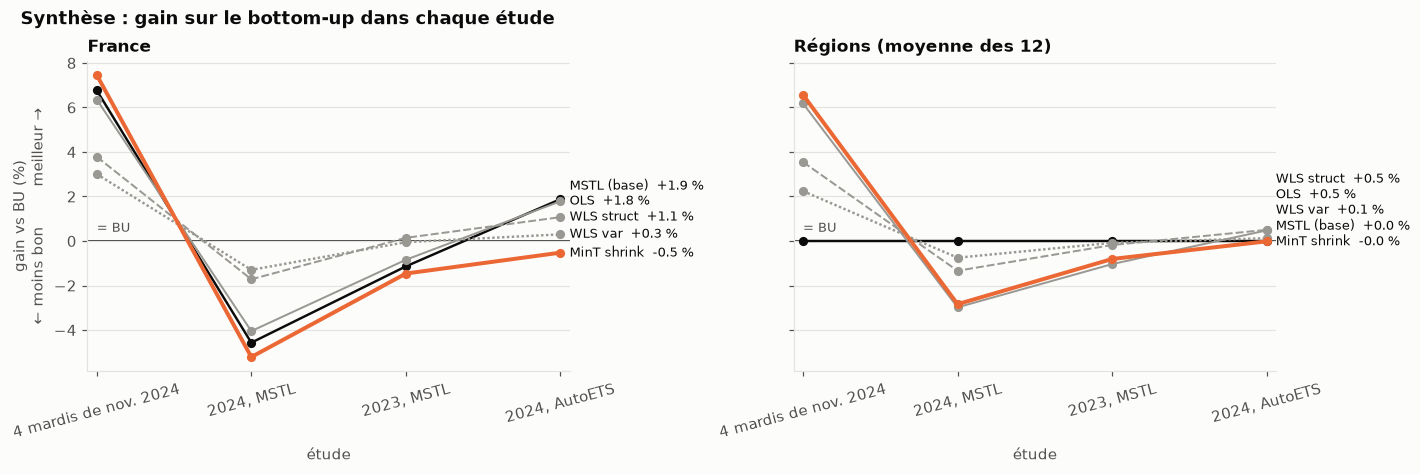

In [19]:
summary = bm.study_summary({STUDIES[w]: data[w][2] for w in STUDIES}, "BU")
summary["study"] = pd.Categorical(summary["study"], list(STUDIES.values()), ordered=True)
fig = figures.gain_curves(summary, "study", ["base", *RECONCILED], "BU",
                          "Synthèse : gain sur le bottom-up dans chaque étude", "étude",
                          markers=True, xticks="categorical", end_values=True)
for ax in fig.axes:
    ax.tick_params(axis="x", labelrotation=15)
export(fig, "confirmation_synthese"); plt.show()
tab = summary.pivot_table(index="method", columns=["level", "study"], values="gain", observed=True)
display((tab.loc[["base", *RECONCILED]] * 100).style.format("{:+.1f} %")
        .set_caption("Gain agrégé sur le bottom-up (%), par étude ; positif = mieux que BU"))

In [20]:
ranks = pd.concat({STUDIES[w]: bm.rank_probabilities(data[w][2], ["BU", "OLS", "WLS struct", "WLS var",
                                                                     "MinT shrink"], level)["P(meilleure)"]
                   for w in ["robustness", "annee_2023", "ets_2024"] for level in ["Régions"]}, axis=1)
ranks_fr = pd.concat({STUDIES[w]: bm.rank_probabilities(data[w][2], ["base", "BU", "OLS", "WLS struct", "WLS var",
                                                                        "MinT shrink"], "France")["P(meilleure)"]
                      for w in ["robustness", "annee_2023", "ets_2024"]}, axis=1)
display(ranks.style.format("{:.0%}").set_caption("Régions : probabilité d'avoir le meilleur MASE moyen "
                                                 "(bootstrap sur les origines)"))
display(ranks_fr.style.format("{:.0%}").set_caption("France : probabilité d'avoir le meilleur MASE moyen"))

,"2024, MSTL","2023, MSTL","2024, AutoETS"
BU,98%,56%,0%
OLS,0%,0%,46%
WLS struct,0%,9%,40%
WLS var,2%,30%,1%
MinT shrink,0%,4%,12%


,"2024, MSTL","2023, MSTL","2024, AutoETS"
base,0%,0%,90%
BU,94%,44%,1%
OLS,0%,7%,5%
WLS struct,0%,36%,3%
WLS var,6%,10%,0%
MinT shrink,0%,3%,0%


**Lecture de la synthèse.** Chaque point est le gain agrégé d'une méthode sur le bottom-up dans une étude ; les
courbes ne décrivent pas une évolution dans le temps, elles relient les études pour qu'on suive chaque méthode.

- **Les 4 mardis de novembre sont l'exception** : c'est la seule étude où toutes les méthodes battent le
  bottom-up (MinT shrink +7,5 % au niveau France). Sur 119 origines de la même année, toutes perdent.
- **Avec MSTL (2024 et 2023), le bottom-up est toujours au-dessus ou à égalité** : aucune courbe ne passe
  au-dessus de 0 de plus de 0,2 %.
- **Avec AutoETS, toutes les méthodes se resserrent autour du bottom-up** (de −0,5 % à +1,9 %), sans écart
  significatif.

**Point d'attention : le gain agrégé du protocole principal n'est pas le chiffre clé du README.** Sur les
4 mardis, MinT shrink gagne 7,5 % en gain agrégé au niveau France, alors que sa variation *moyenne par
origine*, le chiffre clé du README, est de +0,8 % : il est en moyenne **moins bon** selon cette mesure, et ne
gagne qu'à 2 origines sur 4. Une seule origine, le 12 novembre, pèse 70 % de l'erreur totale du bottom-up, et MinT y
gagne : le gain agrégé ne voit presque qu'elle. C'est le piège du § 2, dans l'autre sens.

Les probabilités d'être la meilleure méthode (bootstrap sur les origines) donnent la même image :

- **2024, MSTL** : le bottom-up est le meilleur avec une probabilité de 94 % (France) et 98 % (régions).
- **2023, MSTL** : il reste le plus probable (44 % et 56 %), mais WLS struct et WLS var sont de sérieux
  concurrents. Le classement est **incertain**, ce que les tests du § 7 disaient déjà.
- **2024, AutoETS** : la prévision directe du total (90 %) au niveau France, OLS et WLS struct (46 % et 40 %)
  en région. Le bottom-up n'a presque aucune chance d'être premier, mais il n'est jamais loin derrière.

### Le bilan des études de confirmation

| Conclusion du bloc 5 | 2024, MSTL | 2023, MSTL | 2024, AutoETS | Verdict |
|---|---|---|---|---|
| Toute réconciliation livre des chiffres cohérents | oui | oui | oui | **confirmé** |
| Le levier principal est le modèle de base | MSTL : 61 % de gain sur SN ; réconciliation : ≤ 5 % | 66 % ; ≤ 1,5 % | 31 % ; ≤ 2 % ; RTE débiaisée devant partout | **confirmé** |
| Le bottom-up est la meilleure réconciliation | oui (P ≈ 94-98 %) | oui ou à égalité, non significatif | non, mais à égalité, non significatif | **nuancé** : jamais battu significativement |
| MinT shrink fait moins bien que BU | −2,8 % (régions), −5,2 % (France) | −0,8 %, −1,5 %, non significatif | −0,0 %, −0,5 % | **confirmé avec MSTL**, absent avec AutoETS |
| La cause est W estimée sur les résidus in-sample | corrélation 0,11 vu / 0,56 réel ; W hors éch. efface le handicap | W hors éch. efface le handicap | corrélation 0,49-0,57 / 0,66 : pas de handicap | **confirmé** par 3 expériences |
| 4 origines ne suffisent pas à classer | gain entre −10,8 % et +4,3 % | entre −8,7 % et +6,0 % | | **confirmé** |
| *Nouveau* : le classement dépend de l'horizon | MSTL direct et MinT gagnent h = 1-6 au niveau France | idem, plus marqué | profil inverse | **propre à MSTL** |

**À retenir : ce que le benchmark change à la recommandation.**

1. **Livrer le bottom-up reste la bonne recommandation**, et elle sort renforcée : sur 3 études et
   356 origines, il n'est jamais battu de façon significative, et il est le plus simple à défendre. Ce qui
   s'affaiblit, c'est l'idée que les autres méthodes le battent *nettement* : en 2023 ou avec AutoETS, choisir
   entre BU, WLS et OLS ne change presque rien.
2. **Ne pas utiliser `mint_shrink` sur les résidus in-sample d'un lissage comme MSTL** : la perte se reproduit
   en 2023, et disparaît dès que W voit de vraies erreurs (AutoETS, ou W estimée hors échantillon).
3. **Investir dans le modèle de base** : la prévision de RTE, débiaisée sans fuite, fait 12 à 14 % de mieux que
   la meilleure réconciliation, les deux années. La météo vaut plus que toute réconciliation.
4. **Pour une prévision infra-journalière (h ≤ 6) avec MSTL**, la conclusion pourrait s'inverser : refaire le
   benchmark à cet horizon avant de généraliser.